# 4. Real time

In notebook 3, the chunks came from files. Here they come live, packet by packet, as an
interrogator sends them. There is no interrogator behind this notebook: `replay.py` plays the
two cables as if they were live, in an endless loop of 3.5 min, stamped with the current UTC
time. The earthquake comes back at every loop.

Before you start, open a terminal in this folder and leave this running:

```
uv run replay.py
```

| Stream | Address | Array |
|---|---|---|
| N | `tcp://localhost:5556` | `(time, distance)`, 100 Hz, packets of 0.24 s |
| S | `tcp://localhost:5557` | `(time, distance)`, 62.5 Hz, packets of 0.384 s |

In this notebook you will:
1. receive packets from a stream,
2. give them back the cable geometry,
3. pick them one at a time with the pipeline of notebook 3,
4. follow both cables live, with a waterfall and a map that update by themselves,
5. measure how fast the earthquake is located.

> `uv run replay.py --speedup 4` plays four times faster: handy to test, but the stream times
> then run ahead of the clock.

In [1]:
# solutions only: run from the exercises folder
%cd ..

/home/trabatto/projects/indonesia/lmi-sir


In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sp
import xdas as xd
from IPython.display import clear_output
from xdas.atoms import Atom, State
from xdas.io.asn import ZMQSubscriber

from tools import Locator

What you wrote in notebook 3. The pipeline is split in two: the preprocessing, whose output
we will also plot, and the detector (STA/LTA and trigger). They are functions because each
cable needs its own atoms: each atom keeps the state of one stream.

In [3]:
class STALTA(Atom):
    def __init__(self, sta, lta):
        super().__init__()
        self.sta = sta
        self.lta = lta
        self.short = State(...)
        self.long = State(...)
        self.count = State(...)

    def initialize(self, da, **flags):
        self.short = State(np.zeros((1, da.sizes["distance"])))
        self.long = State(np.zeros((1, da.sizes["distance"])))
        self.count = State(0)

    def call(self, da, **flags):
        dt = da["time"].get_sampling_interval()
        csta, clta = dt / self.sta, dt / self.lta
        power = da.values ** 2
        short, zshort = sp.lfilter([csta], [1, csta - 1], power, axis=0, zi=self.short)
        long, zlong = sp.lfilter([clta], [1, clta - 1], power, axis=0, zi=self.long)
        self.short = State(zshort)
        self.long = State(zlong)
        ratio = short / long
        ratio[: max(round(self.lta / dt) - self.count, 0)] = 0  # the long average is not settled yet
        self.count = State(self.count + len(ratio))
        return da.copy(data=ratio)


def make_pipeline():
    return (
        xd.filter(..., (2.0, 15.0), dim="time")
        >> xd.filter(..., (None, 0.01), dim="distance")
        >> xd.resample(..., 50.0, dim="time")
        >> xd.resample(..., interval=45.0, snap=True, dim="distance")
    )


def make_detector():
    return STALTA(sta=0.2, lta=5.0) >> xd.trigger(
        ..., thresh=8.0, coords=["distance", "longitude", "latitude", "depth", "time"]
    )


abyss = xd.open("abyss.nc")
keep = {"N": slice(5000, 97000), "S": slice(5000, 130000)}
ports = {"N": 5556, "S": 5557}

## Listen

The replay speaks the protocol of an ASN OptoDAS interrogator, as a real one would. A
`ZMQSubscriber` connects to a stream; it is an iterator: each `next` waits for the next packet
and returns it as a `DataArray`.

**Task:** subscribe to the north cable and receive one packet. What are its dimensions, its
duration, its coordinates? How late is its last sample, compared with the clock?

> **Reminder:**
> ```python
> subscriber = ZMQSubscriber("tcp://localhost:1234")   # connect to the stream on port 1234
> packet = next(subscriber)                            # wait for the next packet
> np.datetime64("now", "ns")                           # the clock (UTC)
> da["time"].values[-1]                                # the last time of da
> ```

📖 [Streaming](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/streaming.html) ·
[`xdas.io.asn.ZMQSubscriber`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.io.asn.ZMQSubscriber.html)

In [4]:
subscriber = ZMQSubscriber(f"tcp://localhost:{ports['N']}")
packet = next(subscriber)
print(np.datetime64("now", "ns") - packet["time"].values[-1])
subscriber.close()  # or the packets pile up in memory
packet

-510000000 nanoseconds


<xdas.DataArray (time: 24, distance: 6664)>
[[ -0.58374   -0.552246   0.041748 ...  -0.297028  -0.819061  -2.796661]
 [  7.949463   7.695312  -0.265869 ...  -2.119598  -1.095856   0.398346]
 [ 16.200928  16.142578  -0.091553 ...  -0.926056  -1.091888  -1.245514]
 ...
 [ -7.051422  -7.210419  -0.148468 ...  -0.581116  -2.057312  -2.117706]
 [-19.244965 -19.079132   0.174347 ...  -0.586609   0.392029   0.343781]
 [  4.226776   4.17691   -0.051422 ...  -1.419495   3.230286   2.4664  ]]
Coordinates:
  * time (time): 2026-10-23T22:42:51.280 to 2026-10-23T22:42:51.510
  * distance (distance): 0.000 to 102073.848

## Geometry

The interrogator only knows time and distance along the fiber: where each channel lies is our
metadata, attached in notebook 1. The packets have the same distances as `abyss`, so its
coordinates can be copied over.

**Task:** write `attach(packet, cable)`, which adds the longitude, latitude and depth of the
cable to a packet, and keeps only the channels in the sea (`keep`).

> **Reminder:**
> ```python
> da.assign_coords(name=coordinate)   # add a coordinate, e.g. abyss["N"]["depth"]
> da.sel(distance=slice(a, b))        # select along distance
> ```

In [5]:
def attach(packet, cable):
    packet = packet.assign_coords(
        longitude=abyss[cable]["longitude"],
        latitude=abyss[cable]["latitude"],
        depth=abyss[cable]["depth"],
    )
    return packet.sel(distance=keep[cable])


attach(packet, "N")

<xdas.DataArray (time: 24, distance: 6005)>
[[ -8.2547    -9.907898  -5.264954 ...   0.582306   0.573334   0.316498]
 [ -8.236511 -10.266907  -5.54364  ...   0.525238   0.381134   0.118683]
 [ -8.226135 -10.60321   -5.662415 ...   0.54068    0.40451    0.461639]
 ...
 [ -9.624817 -11.499725  -6.236481 ...  -0.355988   0.037506  -0.016571]
 [ -9.418152 -11.635773  -6.431732 ...  -0.647186  -0.502106  -0.316193]
 [ -9.43634  -11.529388  -6.466095 ...  -0.812653  -0.779755  -0.454193]]
Coordinates:
  * time (time): 2026-10-23T22:42:51.280 to 2026-10-23T22:42:51.510
  * distance (distance): 5009.477 to 96987.773
    longitude (distance): [-71.27829776 ... -71.73282107]
    latitude (distance): [-29.88806179 ... -29.28055922]
    depth (distance): [   5.8 ... 1526.1]

## Packet by packet

A pipeline called with `chunk_dim="time"` takes the next chunk of a stream and keeps its state:
exactly what we need for packets.

**Task:** for 50 packets of the north cable, run the preprocessing then the detector on each
packet, and print the number of picks and the processing time. Is it faster than the
0.24 s between two packets?

> **Reminder:**
> ```python
> for packet in subscriber:          # loop over the packets as they come (never ends)
>     ...
>     if count == 50:
>         break                      # leave the loop
> tic = time.time()                  # the clock in seconds; time.time() - tic: elapsed time
> ```

In [6]:
subscriber = ZMQSubscriber(f"tcp://localhost:{ports['N']}")
pipeline = make_pipeline()
detector = make_detector()
for count, packet in enumerate(subscriber):
    tic = time.time()
    processed = pipeline(attach(packet, "N"), chunk_dim="time")
    picks = detector(processed, chunk_dim="time")
    print(packet["time"].values[0], len(picks), "picks", f"{time.time() - tic:.3f} s")
    if count == 50:
        break
subscriber.close()

2026-10-23T22:42:51.520000000 0 picks 0.029 s


2026-10-23T22:42:51.760000000 0 picks 0.032 s


2026-10-23T22:42:52.000000000 0 picks 0.027 s


2026-10-23T22:42:52.240000000 0 picks 0.027 s


2026-10-23T22:42:52.480000000 0 picks 0.027 s


...

2026-10-23T22:43:02.560000000 0 picks 0.028 s


2026-10-23T22:43:02.800000000 0 picks 0.025 s


2026-10-23T22:43:03.040000000 0 picks 0.029 s


2026-10-23T22:43:03.280000000 0 picks 0.028 s


2026-10-23T22:43:03.520000000 0 picks 0.029 s


## Live

Now both cables at once, with a live display. The two streams do not tick together (a packet
every 0.24 s on N, every 0.384 s on S), and drawing takes time: while we draw, packets queue
up. So each turn of the loop takes *all* the packets waiting on each stream, then redraws once.
With `subscriber.timeout = 0`, `next` does not wait: if no packet is waiting, it raises a
`TimeoutError`.

The display is given: `draw` shows the last minute of each cable (in a `windows` dict, with
their picks) and a map with the located earthquake. To keep it light, the windows hold one
channel out of 4.

To redraw a figure in a loop, the cell output is erased first with `clear_output(wait=True)`
(`wait=True` keeps the old figure until the new one is ready, so it does not flicker).

In [7]:
SPAN = np.timedelta64(60, "s")  # height of the waterfalls
topo = xd.open("data/topo/GMRT.nc")[::4, ::4]  # coarser: faster to draw
cmap = plt.get_cmap("Blues_r").with_extremes(over="lightgray")


def draw(windows, picks, location, now):
    fig, axes = plt.subplots(1, 3, figsize=(15, 6), width_ratios=[1, 1, 0.8])
    for ax, cable in zip(axes, ["N", "S"]):
        if windows[cable] is not None:
            windows[cable].plot(ax=ax, cmap="seismic", vmin=-5, vmax=5, yincrease=False, add_colorbar=False)
        if len(picks):
            mine = picks[(picks["cable"] == cable) & (picks["time"] > now - SPAN)]
            ax.plot(mine["distance"], mine["time"], "k.", markersize=1)
        ax.set_xlim(keep[cable].start, keep[cable].stop)
        ax.set_ylim(now, now - SPAN)  # the last minute, newest at the bottom
        ax.set_title(cable)

    ax = axes[2]
    topo.plot(ax=ax, cmap=cmap, vmin=-6000, vmax=0, add_colorbar=False)
    for cable in abyss:
        ax.plot(abyss[cable]["longitude"].values, abyss[cable]["latitude"].values, color="red", linewidth=2.5)
    ax.plot(-71.800, -29.954, "*", color="gold", markeredgecolor="k", markersize=18)  # EMSC
    if location is not None:
        ax.plot(location["longitude"], location["latitude"], "*", color="red", markeredgecolor="k", markersize=18)
        ax.set_title(f"{location['depth'] / 1000:.0f} km deep, origin {str(location['time'])[11:22]}")
    ax.set_xlim(-72.3, -71.1)
    ax.set_ylim(-31.0, -29.1)
    ax.set_aspect("equal")
    fig.tight_layout()
    plt.show()

**Task:** complete the loop. For each packet: attach the geometry, preprocess, detect (keep the
picks of the turn in `new`, with their cable), and add the preprocessed packet to the window of
its cable, keeping only the last minute. After each turn, give the new picks to the locator and
redraw. The loop runs until 15 s after the first location: up to 4 min, as the earthquake comes
back every 3.5 min. Watch the waves sweep the cables, the picks, and then the location.

> **Reminder:**
> ```python
> table["column"] = value                    # a column with the same value on every row
> xd.concatenate([a, b], dim="time")         # b after a
> da.sel(time=slice(start, None))            # everything after start
> location = locator(new_picks, now)         # a location, or None (notebook 3)
> ```

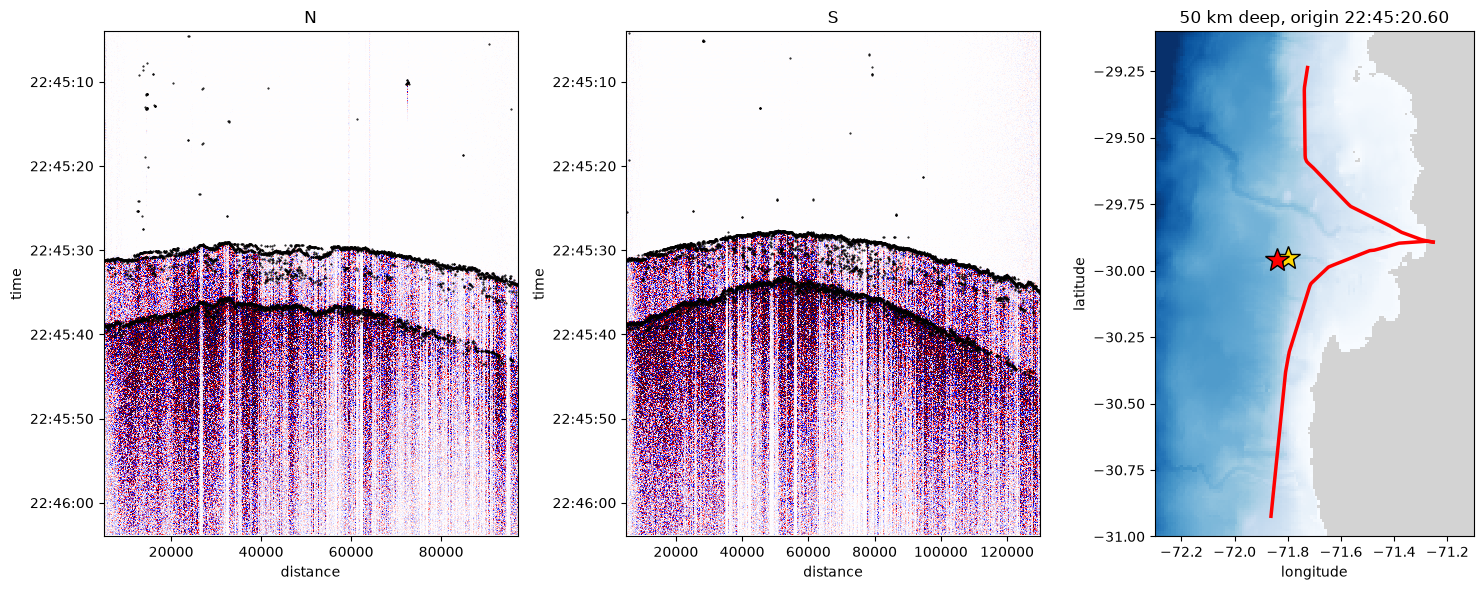

In [8]:
subscribers = {cable: ZMQSubscriber(f"tcp://localhost:{port}") for cable, port in ports.items()}
for subscriber in subscribers.values():
    subscriber.timeout = 0  # next() returns at once, or raises TimeoutError
pipelines = {cable: make_pipeline() for cable in subscribers}
detectors = {cable: make_detector() for cable in subscribers}
windows = {cable: None for cable in subscribers}
locator = Locator()
picks, location, found = pd.DataFrame(), None, None
now = None

try:
    while found is None or now - found < np.timedelta64(15, "s"):  # until 15 s after the location
        new = []
        for cable, subscriber in subscribers.items():
            while True:  # all the packets that arrived while drawing
                try:
                    packet = next(subscriber)
                except TimeoutError:
                    break
                now = packet["time"].values[-1]
                processed = pipelines[cable](attach(packet, cable), chunk_dim="time")
                table = detectors[cable](processed, chunk_dim="time")
                table["cable"] = cable
                new.append(table)
                small = processed[:, ::4]  # lighter to draw
                window = small if windows[cable] is None else xd.concatenate([windows[cable], small], dim="time")
                windows[cable] = window.sel(time=slice(now - SPAN, None))
        if not new:
            time.sleep(0.05)  # nothing new yet: do not spin
            continue
        new = pd.concat(new, ignore_index=True)
        picks = pd.concat([picks, new], ignore_index=True)
        result = locator(new, now)
        if result is not None:
            location, found = result, now
        clear_output(wait=True)
        draw(windows, picks, location, now)
finally:
    for subscriber in subscribers.values():
        subscriber.close()

## How fast?

`found` is the stream time at which the location came out, `location["time"]` the origin time
it found.

**Task:** how many seconds after the earthquake was it located? Where does that time go? The
`Locator` waits 20 s after the burst of picks (`Locator(wait=...)`): try a shorter wait and run
the loop again. What do you gain, and what do you lose?

In [9]:
print(location)
(found - location["time"]).total_seconds()

longitude                        -71.84
latitude                         -29.96
depth                           50000.0
time         2026-10-23 22:45:20.600000
picks                              4707
dtype: object


27.664